# VandaXasset — Bulk Data on S3

VandaXasset measures **who owns what, and how crowded it is**, across equities, fixed income, FX and
commodities. It ships as two families of data:

| Family | What it is | Typical unit |
|---|---|---|
| **Positioning** | Vanda's *combined positioning* score per market, sector, tenor or currency pair: one number that blends every investor type we track | z-score (σ from the series' own history) |
| **Flow** | The underlying investor-type building blocks: foreign vs domestic flows, CFTC trader categories, CTA and risk-parity exposure, dealer gamma, short interest, fund flows | USD mn, contracts, % of AUM |

This notebook shows how to read the **bulk parquet export** that is available for offline research and backtesting.
It covers:

1. Credentials and configuration
2. How the bucket is laid out, and the row schema
3. Discovering datasets through the catalogues
4. Reading positioning data with plain `pyarrow`, and the one trap to know about
5. Reading flow data with push-down filters
6. Dataset versions and mixed frequencies
7. Pulling a local copy

The REST API and Python SDK are covered in the next notebook.

## 1. Credentials & configuration

The sample bucket is private. Vanda issues AWS credentials with your data licence. Provide them in the usual AWS way,
either as environment variables or as a named profile in `~/.aws/credentials`:

```bash
export AWS_ACCESS_KEY_ID=...
export AWS_SECRET_ACCESS_KEY=...
export AWS_DEFAULT_REGION=us-east-1
```

Never paste keys into a notebook you might share. Copy `.env.example` to `.env`, which git ignores.

Every notebook in this kit reads through the small helper module `quantkit.py` at the repo root. By default it reads straight
from S3. To work offline, sync the bucket once and point `VXA_DATA_ROOT` at the local folder:

```bash
aws s3 sync s3://vanda-analytics-samples/vandaxasset/ ./data/vandaxasset/
export VXA_DATA_ROOT=./data/vandaxasset
```

The full sample is about **200 MB** of parquet.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as pads
import pyarrow.compute as pc

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()

print("Reading from:", qk.DATA_ROOT)

Reading from: s3://vanda-analytics-samples/vandaxasset


## 2. Bucket layout & schema

```
s3://vanda-analytics-samples/vandaxasset/
├── catalog/
│   ├── flow.parquet          (+ .csv)    one row per flow dataset
│   └── positioning.parquet   (+ .csv)    one row per positioning dataset
├── flow/layout=v1/
│   └── asset_class=<equity|fixed_income|fx|commodity|multi_asset>/
│       └── dataset=<name>/dataset_version=<n>/
│           └── year=YYYY/month=MM/data.parquet
└── positioning/layout=v1/
    └── asset_class=<...>/dataset=<name>/dataset_version=<n>/data.parquet
```

Folder names are [Hive-style partitions](https://arrow.apache.org/docs/python/dataset.html#partitioned-datasets), so `pyarrow`,
`polars`, DuckDB, Spark and Athena can all read the tree directly and turn the folder names into columns.

Every file in both families shares one **long-format** schema, with one row per *(date, series, metric)*:

| Column | Meaning |
|---|---|
| `ts` | Observation date (UTC midnight) |
| `series_label` | Vanda series code, e.g. `USEQCOMB` or `KREQSTCKFORMIXMIXMIX`. **This is the key to join on.** |
| `vanda_id` | Stable numeric identifier for the series |
| `dataset_id` | Dataset the series belongs to, e.g. `POS.US.EQ.COMB.V1` |
| `entity`, `entity_type` | What the row describes: an instrument, sector, investor type and so on |
| `metric`, `unit` | e.g. `net` in `USDmn`, `combined_positioning` in `zscore` |
| `measure_class` | Flow only: `flow`, `exposure`, `ratio`, `signal`, ... |
| `frequency` | `daily`, `weekly`, `bi-weekly` or `monthly` |
| `value` | The number |
| `is_pit` | Positioning only: `True` for the point-in-time value as first published, `False` for the restated value |
| `published_at` | When the row was written |

## 3. Discover datasets through the catalogues

Start every piece of research from the catalogue rather than from folder listings. It tells you which
`dataset_version` is current and the coverage window of each dataset.

In [2]:
positioning_catalog = qk.load_catalog("positioning")
flow_catalog = qk.load_catalog("flow")

print(f"{len(positioning_catalog)} positioning datasets, {len(flow_catalog)} flow datasets")
positioning_catalog[["asset_class", "dataset", "dataset_version", "display_name", "dataset_id", "first_ts", "last_ts"]].head(12)

41 positioning datasets, 32 flow datasets


,asset_class,dataset,dataset_version,display_name,dataset_id,first_ts,last_ts
0,commodity,global_commodity_positioning,1,Global Commodities Combined Positioning,POS.GL.COM.COMB.V1,2010-01-01 00:00:00+00:00,2026-04-10 00:00:00+00:00
1,commodity,global_metals_positioning,1,LME Metals Combined Positioning,POS.GL.LME.COMB.V1,2010-01-01 00:00:00+00:00,2026-04-10 00:00:00+00:00
2,equity,au_equity_positioning,1,Australia Equity Combined Positioning,POS.AU.EQ.COMB.ALL.V1,2011-01-03 00:00:00+00:00,2026-04-10 00:00:00+00:00
3,equity,cn_a_share_positioning,1,China A-Shares Combined Positioning,POS.CN.EQ.COMB.A.V1,2015-01-01 00:00:00+00:00,2026-04-10 00:00:00+00:00
4,equity,cn_a_share_sector_positioning,1,China A-Shares Combined Positioning - Sectors,POS.CN.EQ.COMB.A.SECTORS.V1,2016-06-01 00:00:00+00:00,2026-04-10 00:00:00+00:00
5,equity,cn_h_share_positioning,1,China H-Shares Combined Positioning,POS.CN.EQ.COMB.H.V1,2010-01-01 00:00:00+00:00,2026-04-10 00:00:00+00:00
6,equity,cn_h_share_sector_positioning,1,China H-Shares Combined Positioning - Sectors,POS.CN.EQ.COMB.H.SECTORS.V1,2011-12-28 00:00:00+00:00,2026-04-10 00:00:00+00:00
7,equity,eafe_equity_positioning,1,EAFE Equity Combined Positioning,POS.EAFE.EQ.COMB.V1,2010-01-01 00:00:00+00:00,2026-04-10 00:00:00+00:00
8,equity,em_equity_positioning,1,EM Equity Combined Positioning,POS.EM.EQ.COMB.V1,2008-04-08 00:00:00+00:00,2026-04-10 00:00:00+00:00
9,equity,eu_equity_positioning,2,Europe Equity Combined Positioning,POS.EU.EQ.COMB.V2,2010-01-01 00:00:00+00:00,2026-04-10 00:00:00+00:00


In [3]:
summary = (
    qk.load_datasets()
    .groupby(["asset_class", "family"])
    .size()
    .unstack(fill_value=0)
)
summary.loc["total"] = summary.sum()
summary

family,flow,positioning
asset_class,,
commodity,1,2
equity,17,21
fixed_income,7,17
fx,0,1
multi_asset,7,0
total,32,41


The kit also ships a **series-level dictionary** in `Reference Data/`, with a name, description, investor taxonomy, metrics and
coverage for each of the ~1,240 series. Notebook 02 walks through it.

In [4]:
ref = qk.series_reference()
ref.groupby(["family", "asset_type"]).size().unstack(fill_value=0)

asset_type,COM,CRYPTO,EQ,FI,FX
family,,,,,
flow,157,10,612,148,76
positioning,23,0,155,29,28


## 4. Read positioning with plain `pyarrow`

The helper module is optional. Here is a dataset read without it, so you can see exactly what happens.

In [5]:
fs, base = qk.filesystem()
entry = positioning_catalog.set_index("dataset").loc["us_equity_positioning"]

path = (
    f"{base}/positioning/layout=v1/asset_class={entry.asset_class}"
    f"/dataset=us_equity_positioning/dataset_version={entry.dataset_version}"
)
raw = pads.dataset(path, filesystem=fs, format="parquet").to_table().to_pandas()
raw.head()

,ts,dataset_id,vanda_id,series_label,entity,entity_type,metric,value,unit,frequency,is_pit,published_at
0,2010-01-01 00:00:00+00:00,POS.US.EQ.COMB.V1,VNDA2945515953,USEQCOMB,USEQCOMB,aggregate,combined_positioning,0.051221,zscore,daily,False,2026-10-10 13:17:16.126408+00:00
1,2010-01-04 00:00:00+00:00,POS.US.EQ.COMB.V1,VNDA2945515953,USEQCOMB,USEQCOMB,aggregate,combined_positioning,0.037217,zscore,daily,False,2026-10-10 13:17:16.126408+00:00
2,2010-01-05 00:00:00+00:00,POS.US.EQ.COMB.V1,VNDA2945515953,USEQCOMB,USEQCOMB,aggregate,combined_positioning,0.080696,zscore,daily,False,2026-10-10 13:17:16.126408+00:00
3,2010-01-06 00:00:00+00:00,POS.US.EQ.COMB.V1,VNDA2945515953,USEQCOMB,USEQCOMB,aggregate,combined_positioning,0.126876,zscore,daily,False,2026-10-10 13:17:16.126408+00:00
4,2010-01-07 00:00:00+00:00,POS.US.EQ.COMB.V1,VNDA2945515953,USEQCOMB,USEQCOMB,aggregate,combined_positioning,0.274392,zscore,daily,False,2026-10-10 13:17:16.126408+00:00


### ⚠️ The one trap: two revisions in the same file

Positioning files carry **two rows per date** for most series: the *restated* value (`is_pit = False`), recomputed with
today's model and history, and the *point-in-time* value (`is_pit = True`), as it was first published. Mix them and
every chart and statistic is wrong in a way that is hard to spot.

In [6]:
rows_per_date = raw.groupby("ts").size().value_counts().rename("dates").rename_axis("rows per date")
print(rows_per_date, "\n")
raw.groupby("is_pit").agg(rows=("value", "size"), first=("ts", "min"), last=("ts", "max"))

rows per date
2    3465
1     781
Name: dates, dtype: int64 



,rows,first,last
is_pit,,,
False,4246,2010-01-01 00:00:00+00:00,2026-04-10 00:00:00+00:00
True,3465,2012-12-31 00:00:00+00:00,2026-04-10 00:00:00+00:00


Pick one revision explicitly. `qk.load` does this for you, defaulting to `restated`, and also pushes the filter into the
parquet scan so the unwanted rows are never read:

restated rows: 4246 | point-in-time rows: 3465
duplicate dates after filtering: 0


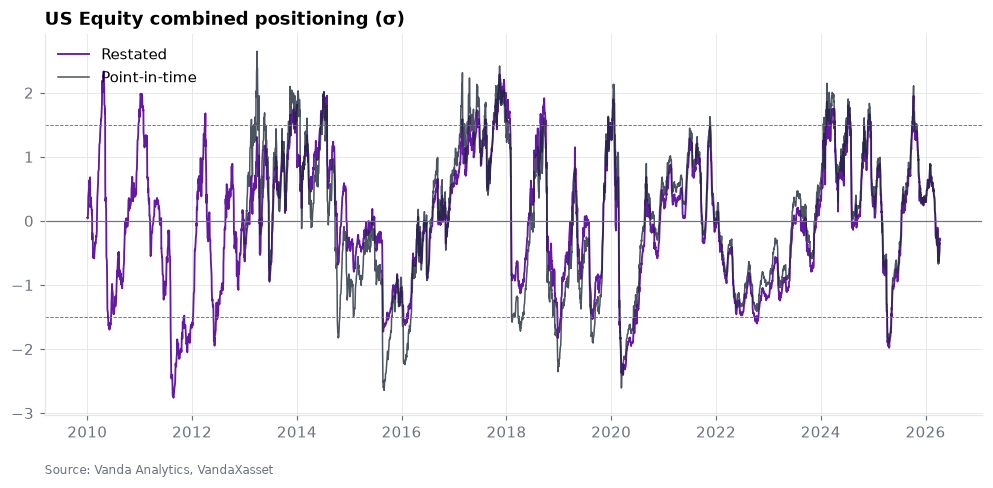

In [7]:
us = qk.load("positioning", "us_equity_positioning")
us_pit = qk.load("positioning", "us_equity_positioning", revision="point_in_time")

print("restated rows:", len(us), "| point-in-time rows:", len(us_pit))
print("duplicate dates after filtering:", us.duplicated(["series_label", "ts"]).sum())

fig, ax = plt.subplots()
ax.plot(us.ts, us.value, label="Restated", lw=1.2)
ax.plot(us_pit.ts, us_pit.value, label="Point-in-time", lw=1.0, alpha=0.8)
ax.axhline(0, color=qk.VANDA["sub"], lw=0.8)
for level in (-qk.CROWDING_THRESHOLD, qk.CROWDING_THRESHOLD):
    ax.axhline(level, color=qk.VANDA["sub"], lw=0.6, ls="--")
ax.set_title("US Equity combined positioning (σ)")
ax.legend(loc="upper left")
qk.source_note(ax)
plt.show()

Notebook 04 shows why the difference between the two lines matters for backtests.

## 5. Read flow data with push-down filters

Flow datasets are partitioned by `year` and `month`, and some are large: `global_systematic_flows` holds roughly 19 million
rows. Filter on `series`, `metrics` and dates so that only the files and row groups you need are read.

**Example:** foreign investors in Japanese equities (cash) from the Japan weekly investor flows dataset.

In [8]:
jp_label = "JPEQSTCKFORINSMIXMIX"
print(qk.describe(jp_label)[["name", "description", "dataset", "frequency", "metrics", "units"]], "\n")

jp = qk.load("flow", "jp_investor_flows", series=jp_label, metrics="net", start="2015-01-01")
jp.tail()

name                          Japan Foreign Institutional Equity
description    Foreign Institutional investors' flows into Ja...
dataset                                        jp_investor_flows
frequency                                                  daily
metrics                                       buy;net;sell;total
units                                                      USDmn
Name: 766, dtype: object 



,ts,series_label,entity,entity_type,metric,value,unit,frequency,is_pit,dataset_id,vanda_id,published_at
582,2026-03-13,JPEQSTCKFORINSMIXMIX,JPEQSTCKFORINSMIXMIX,aggregate,net,-3072.711519,USDmn,daily,False,FLOW.JP.JPWOW.V1,VNDA3427686290,2026-10-01 10:38:27.725380+00:00
583,2026-03-19,JPEQSTCKFORINSMIXMIX,JPEQSTCKFORINSMIXMIX,aggregate,net,-3291.162727,USDmn,daily,False,FLOW.JP.JPWOW.V1,VNDA3427686290,2026-10-01 10:38:27.725380+00:00
584,2026-03-27,JPEQSTCKFORINSMIXMIX,JPEQSTCKFORINSMIXMIX,aggregate,net,-9413.167145,USDmn,daily,False,FLOW.JP.JPWOW.V1,VNDA3427686290,2026-10-01 10:38:27.725380+00:00
585,2026-04-03,JPEQSTCKFORINSMIXMIX,JPEQSTCKFORINSMIXMIX,aggregate,net,11993.196969,USDmn,daily,False,FLOW.JP.JPWOW.V1,VNDA3427686290,2026-10-01 10:38:27.725380+00:00
586,2026-04-10,JPEQSTCKFORINSMIXMIX,JPEQSTCKFORINSMIXMIX,aggregate,net,10308.424010,USDmn,daily,False,FLOW.JP.JPWOW.V1,VNDA3427686290,2026-10-01 10:38:27.725380+00:00


**Check the cadence before choosing a window.** Japan's MoF investor flows are released weekly. The median gap between
observations tells you the effective cadence of any series, which is what a rolling window measured in observations
depends on:

In [9]:
jp_net = jp.set_index("ts")["value"]
print("median days between observations:", jp_net.index.to_series().diff().dt.days.median())

median days between observations: 7.0


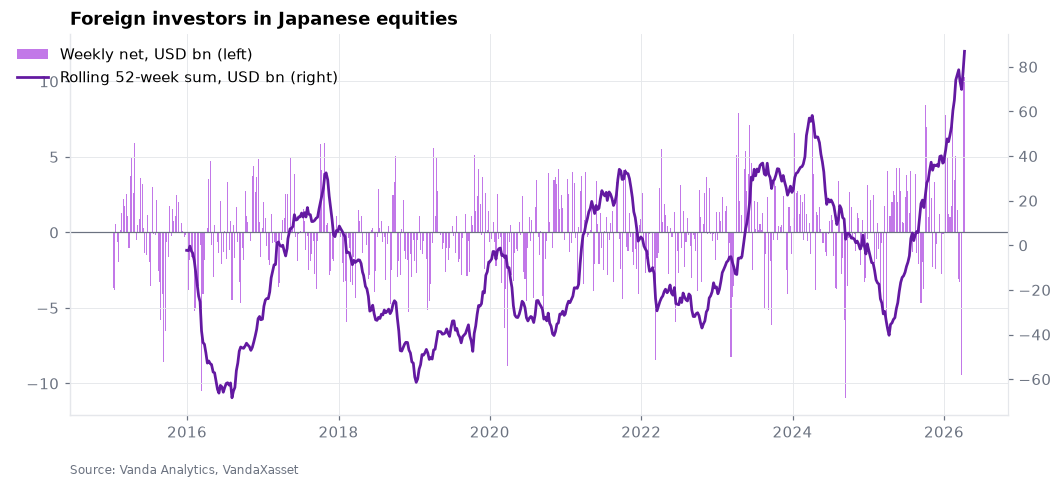

In [10]:
rolling_52w = jp_net.rolling(52).sum() / 1_000

fig, ax = plt.subplots()
ax.bar(jp_net.index, jp_net / 1_000, width=5, color=qk.VANDA["lilac"], label="Weekly net, USD bn (left)")
ax.axhline(0, color=qk.VANDA["sub"], lw=0.8)
ax2 = ax.twinx()
ax2.plot(rolling_52w.index, rolling_52w, color=qk.VANDA["purple"], lw=1.8, label="Rolling 52-week sum, USD bn (right)")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("Foreign investors in Japanese equities")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.88))
qk.source_note(ax)
plt.show()

## 6. Versions and mixed frequencies

### Versions
When Vanda improves a model, the new version is published **alongside** the old one, never over it. That gives you time to
compare. The catalogue's `dataset_version` names the current one. Here are Europe's v1 and v2 side by side:

Correlation v1 vs v2: 0.87 over 4,243 days


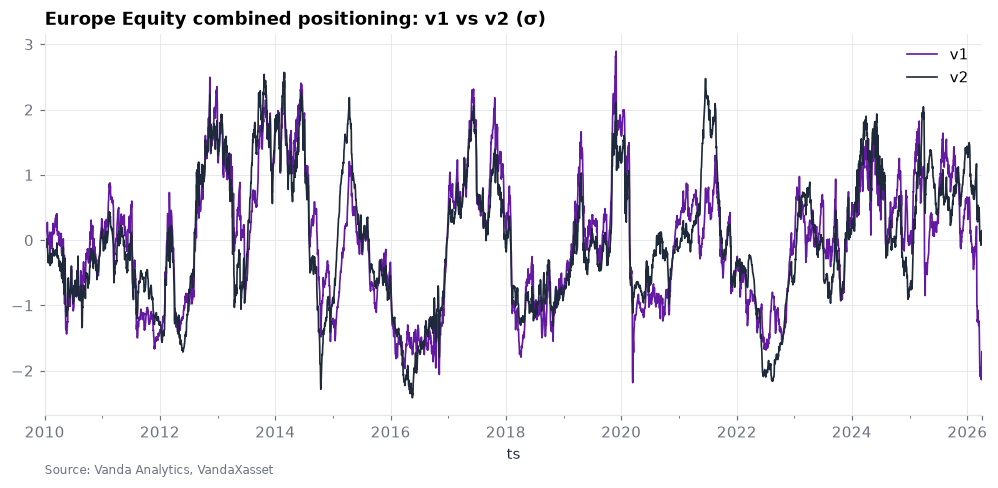

In [11]:
eu_v1 = qk.load("positioning", "eu_equity_positioning", series="EUEQCOMB", version=1)
eu_v2 = qk.load("positioning", "eu_equity_positioning", series="EUEQCOMB", version=2)

both = pd.concat({"v1": eu_v1.set_index("ts").value, "v2": eu_v2.set_index("ts").value}, axis=1).dropna()
print(f"Correlation v1 vs v2: {both.corr().iloc[0, 1]:.2f} over {len(both):,} days")

ax = both.plot(lw=1.1, title="Europe Equity combined positioning: v1 vs v2 (σ)")
qk.source_note(ax)
plt.show()

### Mixed frequencies inside one dataset
A few datasets mix cadences. Australia's aggregate positioning is daily while its sectors are weekly, and India's sectors
are bi-weekly. Check `frequency` before you compute rolling windows measured in observations:

In [12]:
au = qk.load("positioning", "au_equity_positioning")
au.groupby(["frequency"]).agg(series=("series_label", "nunique"), rows=("value", "size"))

,series,rows
frequency,,
daily,1,3984
weekly,11,6479


## 7. Pull a local copy

`aws s3 sync` (section 1) is the simplest way to take a copy. If you want one consolidated file per family, the loop below
reads each dataset's current version and writes a single parquet file. Here it is limited to positioning, which is small.
Flow has the same shape but is about 30 million rows, so we recommend keeping it partitioned.

In [13]:
out_dir = Path("output")
out_dir.mkdir(exist_ok=True)

frames = [qk.load("positioning", ds).assign(dataset=ds) for ds in positioning_catalog["dataset"]]
all_positioning = pd.concat(frames, ignore_index=True)
all_positioning.to_parquet(out_dir / "vandaxasset_positioning_restated.parquet", index=False)

print(f"{len(all_positioning):,} rows · {all_positioning.series_label.nunique()} series → {out_dir / 'vandaxasset_positioning_restated.parquet'}")

705,238 rows · 235 series → output/vandaxasset_positioning_restated.parquet


---
**Next:** `01 - Data Access - REST API & Python SDK` for live data, then `02 - Catalogue Tour & Series Taxonomy`.

Documentation: [docs.vanda-analytics.com](https://docs.vanda-analytics.com/) · Python SDK: [`vanda-api`](https://pypi.org/project/vanda-api/)